# 4. Predicting Wine Quality with a Deep MLP

In this exercise, we build a deep MLP to predict wine quality. We will treat this as a regression problem.


In [1]:
import keras
import numpy as np
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
import tensorboard
from itertools import product
import pydot
import pandas as pd


## 4.1 Load the Data

1. Download the [Wine Quality dataset](https://archive.ics.uci.edu/dataset/186/wine+quality) using `keras.utils.get_file()`.
2. Load `winequality-white.csv` into a Pandas DataFrame. We will use the 11 features to predict wine quality, which we view as a real number.
3. What is the distribution of the target variable?
4. Create the tensor of features $X$ and the tensor of targets $y$.
5. Use 20% of the complete dataset as the test set. Use `train_test_split` from scikit-learn.
6. Use 20% of the remaining data as the validation set. Again use `train_test_split`.
7. What are the shapes of the training, validation, and test sets?


In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wine_quality = fetch_ucirepo(id=186) 
  
# data (as pandas dataframes) 
X = wine_quality.data.features 
y = wine_quality.data.targets 

  
# variable information 
print(X) 


      fixed_acidity  volatile_acidity  citric_acid  residual_sugar  chlorides  \
0               7.4              0.70         0.00             1.9      0.076   
1               7.8              0.88         0.00             2.6      0.098   
2               7.8              0.76         0.04             2.3      0.092   
3              11.2              0.28         0.56             1.9      0.075   
4               7.4              0.70         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
6492            6.2              0.21         0.29             1.6      0.039   
6493            6.6              0.32         0.36             8.0      0.047   
6494            6.5              0.24         0.19             1.2      0.041   
6495            5.5              0.29         0.30             1.1      0.022   
6496            6.0              0.21         0.38             0.8      0.020   

      free_sulfur_dioxide  

quality
6    2836
5    2138
7    1079
4     216
8     193
3      30
9       5
Name: count, dtype: int64


array([[<Axes: title={'center': 'quality'}>]], dtype=object)

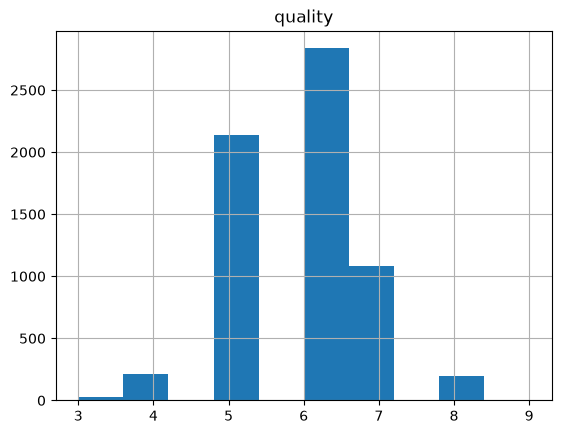

In [3]:
# Source - https://stackoverflow.com/a/28586185
# Posted by will, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-07, License - CC BY-SA 3.0

print(y.value_counts("quality"))
y.hist(column="quality")


In [4]:
import tensorflow as tf
from sklearn.model_selection import train_test_split

X_ = X.to_numpy()
y_ = y.to_numpy()

# Split numpy arrays first, sklearn cannot split TF tensors.
X_, X_test, y_, y_test = train_test_split(
    X_, y_, test_size=0.2, random_state=42)
print(X.shape, X_test.shape, "\n")
X_train, X_val, y_train, y_val = train_test_split(
    X_, y_ , test_size=0.2, random_state=42)
print(X_train.shape, y_val.shape, "\n")

X_train = tf.convert_to_tensor(X_train)
X_test = tf.convert_to_tensor(X_test)
y_train = tf.convert_to_tensor(y_train)
y_test = tf.convert_to_tensor(y_test)

print(X_train.shape)


(6497, 11) (1300, 11) 

(4157, 11) (1040, 1) 

(4157, 11)


## 4.2 Build an MLP

1. Define a `Normalization` layer that ensures that the mean and standard deviation of each feature are close to zero and one, respectively.
2. Adapt this layer only on the training data to prevent data leakage.
3. Use the Sequential API to build a model that starts with the normalization layer, followed by three hidden layers and one output layer. Use the ReLU activation function for the hidden layers, with 50 units each. Choose the appropriate activation function and number of units for the output layer, given that this is a regression problem.
4. Create a function `get_model(normalization_layer)` that returns this model. Note that the normalization layer is passed as an argument.
5. Display the summary of the returned model. It should have 5,774 parameters in total, of which 23 are non-trainable.
6. Make sure that you understand where these numbers come from.


In [5]:
# Define and adapt the normalization layer, then build the model
normalisation_layer = keras.layers.Normalization()

normalisation_layer.adapt(X_train)

def get_model(normalisation_layer):
  model = keras.Sequential()
  model.add(normalisation_layer)
  model.add(keras.layers.Dense(50, activation='relu', name='hidden1'))
  model.add(keras.layers.Dense(50, activation='relu', name='hidden2'))
  model.add(keras.layers.Dense(50, activation='relu', name='hidden3'))
  model.add(keras.layers.Dense(1, name='output'))
  
  return model

model = get_model(normalisation_layer)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (4157, 11)             │            23 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden3 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23 (96.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23 (96.00 B)

## 4.3 Compile the Model

1. Create an Adam optimizer with a learning rate of $1/1000$.
2. Compile the model using mean absolute error as the loss function.


In [6]:
adam = keras.optimizers.Adam(
  learning_rate=0.001
)

model.compile(
  optimizer=adam,
  loss='mae'
)

## 4.4 Train the Model

1. Train the model for 20 epochs using a batch size of 32.
2. Use the `history` object returned by the `fit()` method to plot the learning curves. Is the model overfitting?


In [7]:
batch_size = 32
epochs = 20

callbacks = [
    keras.callbacks.ModelCheckpoint(filepath="model_at_epoch_{epoch}.keras"),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=2),
]

history = model.fit(
      X_train,
      y_train,
      batch_size=batch_size,
      epochs=epochs,
      validation_data=(X_val, y_val)
  )


Epoch 1/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 2.0297 - val_loss: 1.0170
Epoch 2/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 507us/step - loss: 0.8488 - val_loss: 0.8087
Epoch 3/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 491us/step - loss: 0.6906 - val_loss: 0.6830
Epoch 4/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 492us/step - loss: 0.6084 - val_loss: 0.6231
Epoch 5/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 489us/step - loss: 0.5729 - val_loss: 0.5956
Epoch 6/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 483us/step - loss: 0.5505 - val_loss: 0.5802
Epoch 7/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 481us/step - loss: 0.5373 - val_loss: 0.5718
Epoch 8/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 477us/step - loss: 0.5276 - val_loss: 0.5677
Epoch 9/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step - loss: 0.5236 - val_loss: 0.5599
Epoch 10/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 477us/step - loss: 0.5168 - val_loss: 0.5561
Epoch 11/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 477us/step - loss: 0.5132 - val_loss: 0.5525
Epoch 12/20
130/130 ━━━━━━━━━━━━

## 4.5 Evaluate the Model

1. Use the `evaluate()` method to evaluate the model on the test set.
2. What is the mean absolute error on the test set?
3. Calculate the mean absolute error for each of the different wine quality values in the test set. Does the model perform differently depending on the quality of the wine?


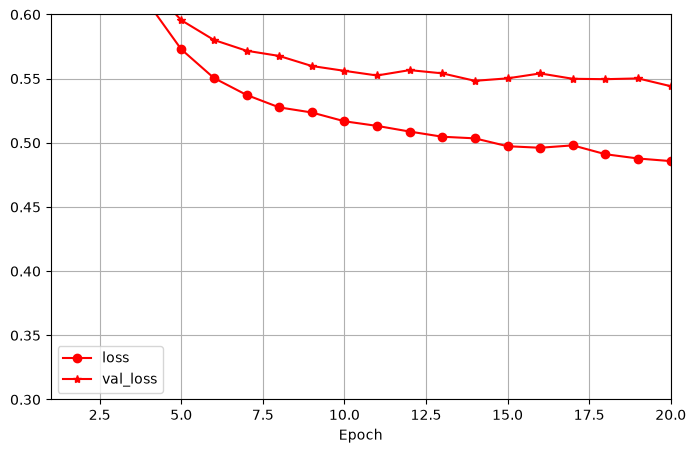

In [8]:
# Evaluate the model and calculate the error for each wine quality

def plot_learning_curves(history):
    plt.figure(figsize=(8, 5))
    for key, style in zip(history.history, ["r-o", "r-*", "b-o", "b-*"]):
        epochs = np.array(history.epoch)
        plt.plot(epochs + 1, history.history[key], style, label=key)

    plt.xlabel("Epoch")
    plt.axis([1, len(history.history["loss"]), 0.3, 0.6])
    plt.legend(loc="lower left")
    plt.grid()

plot_learning_curves(history)

In [9]:
predictions = model.predict(X_test)
predictions.shape

41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 672us/step


(1300, 1)

In [10]:
model.evaluate(X_test, y_test)
  

41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 429us/step - loss: 0.5474


0.5474241971969604

In [11]:
extra_dataset = pd.DataFrame(
    {'real_values': np.asarray(y_test).reshape(-1), 
     'predicted_values': np.asarray(predictions).reshape(-1)})
extra_dataset.head()

,real_values,predicted_values
0,8,5.906311
1,5,5.135682
2,7,6.832105
3,6,5.298933
4,6,5.079022


In [19]:
# add absolute error column
extra_dataset['absolute_error'] = abs(
    extra_dataset['real_values'] - extra_dataset['predicted_values']
)

# group predictions by quality score
predictions_grouped = (
    extra_dataset.groupby('real_values', sort=True)
    .agg(**{
        'mean_predicted values': ('predicted_values', 'mean'),
        'mae': ('absolute_error', 'mean'),
    })
    .rename_axis('score')
    .reset_index()
)

predictions_grouped.head()


,score,mean_predicted values,mae
0,3,6.158212,3.158212
1,4,5.269360,1.269360
2,5,5.355411,0.423029
3,6,5.773755,0.408713
4,7,6.234657,0.771002
